# Notebook 01: Data Understanding

## Objective
In this notebook, we explore the NASA FEMTO bearing dataset to understand:
- Dataset structure and organization
- Raw data format and characteristics
- Vibration signal patterns
- Degradation trends
- Bearing failure progression

This foundational understanding guides feature engineering and model design for RUL prediction.

## 1. Import Libraries & Setup

In [1]:
import os
import sys
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict

# Add src to path for imports
sys.path.insert(0, '../src')
from data_loader import FEMTOInspector

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10

print("✓ Libraries imported successfully")

✓ Libraries imported successfully


## 2. Dataset Inspection

First, let's run the data loader to inspect the dataset structure and validate data quality.

In [2]:
# Run dataset inspection
inspector = FEMTOInspector(data_root="../data/raw")
results = inspector.run_full_inspection()
inspector.print_summary()

NASA FEMTO Bearing Dataset Inspector

DATASET SUMMARY

LEARNING_SET
--------------------------------------------------------------------------------
  Bearing folders: 12
  Total files: 120
  Total rows: 600
  Total size: 0.01 MB

  Bearing Conditions:

    Bearing1_1:
      Files: 10
      Total rows: 50
      Total size: 1.03 KB
      Columns: 3
      Column names: Horizontal_vibration, Vertical_vibration, Timestamp
      Delimiter: ','
      Has header: True

    Bearing1_2:
      Files: 10
      Total rows: 50
      Total size: 1.03 KB
      Columns: 3
      Column names: Horizontal_vibration, Vertical_vibration, Timestamp
      Delimiter: ','
      Has header: True

    Bearing1_3:
      Files: 10
      Total rows: 50
      Total size: 1.03 KB
      Columns: 3
      Column names: Horizontal_vibration, Vertical_vibration, Timestamp
      Delimiter: ','
      Has header: True

    Bearing2_1:
      Files: 10
      Total rows: 50
      Total size: 1.03 KB
      Columns: 3
      Colum

## 3. Explore Dataset Organization

### Learning Set vs Test Set
- **Learning Set**: 4 bearings × 3 operating conditions = 12 bearing conditions
  - Each bearing (1-4) tested under 3 different operational stresses
  - Each contains multiple CSV files (chronological sequence)
  - Used for training models

- **Test Set**: 3 bearings × 2 operating conditions = 6 bearing conditions
  - Different bearings, different conditions
  - Used for evaluating model generalization

Let's visualize this structure:

In [3]:
# Extract structure information
data_root = Path("../data/raw")

# Count files per bearing condition
bearing_stats = {}

for set_name in ['Learning_set', 'Test_set']:
    set_path = data_root / set_name
    bearing_stats[set_name] = {}
    
    for bearing_dir in sorted(os.listdir(set_path)):
        bearing_path = set_path / bearing_dir
        if bearing_path.is_dir():
            csv_files = list(bearing_path.glob('*.csv'))
            bearing_stats[set_name][bearing_dir] = len(csv_files)

# Display statistics
print("\n=== Learning Set ===")
for bearing, count in sorted(bearing_stats['Learning_set'].items()):
    print(f"  {bearing}: {count} files")

print(f"\nTotal Learning files: {sum(bearing_stats['Learning_set'].values())}")

print("\n=== Test Set ===")
for bearing, count in sorted(bearing_stats['Test_set'].items()):
    print(f"  {bearing}: {count} files")

print(f"\nTotal Test files: {sum(bearing_stats['Test_set'].values())}")


=== Learning Set ===
  Bearing1_1: 10 files
  Bearing1_2: 10 files
  Bearing1_3: 10 files
  Bearing2_1: 10 files
  Bearing2_2: 10 files
  Bearing2_3: 10 files
  Bearing3_1: 10 files
  Bearing3_2: 10 files
  Bearing3_3: 10 files
  Bearing4_1: 10 files
  Bearing4_2: 10 files
  Bearing4_3: 10 files

Total Learning files: 120

=== Test Set ===
  Bearing1_1: 5 files
  Bearing1_2: 5 files
  Bearing1_3: 1802 files
  Bearing1_4: 1327 files
  Bearing1_5: 2685 files
  Bearing1_6: 2685 files
  Bearing1_7: 1752 files
  Bearing2_1: 5 files
  Bearing2_2: 5 files
  Bearing2_3: 1202 files
  Bearing2_4: 713 files
  Bearing2_5: 2337 files
  Bearing2_6: 572 files
  Bearing2_7: 200 files
  Bearing3_1: 5 files
  Bearing3_2: 5 files
  Bearing3_3: 410 files

Total Test files: 15715


## 4. Load Sample Data

Let's load a sample bearing condition and examine the data structure:

In [4]:
def load_bearing_data(bearing_path):
    """
    Load all CSV files from a bearing condition folder.
    Returns a list of dataframes in chronological order.
    """
    bearing_path = Path(bearing_path)
    csv_files = sorted(bearing_path.glob('*.csv'))
    
    data_frames = []
    for csv_file in csv_files:
        try:
            df = pd.read_csv(csv_file)
            df['file_index'] = len(data_frames)  # Track file order
            data_frames.append(df)
        except Exception as e:
            print(f"Error loading {csv_file}: {e}")
    
    return data_frames

# Load sample bearing (Bearing1_1 from Learning set)
sample_bearing_path = data_root / "Learning_set" / "Bearing1_1"
bearing1_1_data = load_bearing_data(sample_bearing_path)

print(f"Loaded {len(bearing1_1_data)} files from Bearing1_1")
print(f"\nFirst file shape: {bearing1_1_data[0].shape}")
print(f"\nFirst file (first 5 rows):")
print(bearing1_1_data[0].head())
print(f"\nData types:")
print(bearing1_1_data[0].dtypes)

Loaded 10 files from Bearing1_1

First file shape: (5, 4)

First file (first 5 rows):
   Horizontal_vibration  Vertical_vibration  Timestamp  file_index
0                   0.1                0.15          0           0
1                   0.2                0.30          1           0
2                   0.3                0.45          2           0
3                   0.4                0.60          3           0
4                   0.5                0.75          4           0

Data types:
Horizontal_vibration    float64
Vertical_vibration      float64
Timestamp                 int64
file_index                int64
dtype: object


## 5. Understand Data Characteristics

### Key Observations:
- **Columns**: Horizontal vibration, Vertical vibration, Timestamp
- **Sampling Rate**: 10 kHz (10,000 samples per second)
- **File Interval**: Each file contains a snapshot over a short time window
- **Chronological Order**: Files named sequentially represent time progression

Let's analyze the data statistics:

In [5]:
# Combine all data for statistical overview
all_data = pd.concat(bearing1_1_data, ignore_index=True)

print(f"\nTotal records in Bearing1_1: {len(all_data):,}")
print(f"Time span: {len(bearing1_1_data)} files × {len(bearing1_1_data[0])} samples/file")
print(f"\nStatistical Summary:")
print(all_data[['Horizontal_vibration', 'Vertical_vibration']].describe())

# Check for missing values
print(f"\nMissing values:")
print(all_data.isnull().sum())


Total records in Bearing1_1: 50
Time span: 10 files × 5 samples/file

Statistical Summary:
       Horizontal_vibration  Vertical_vibration
count             50.000000           50.000000
mean               0.300000            0.450000
std                0.142857            0.214286
min                0.100000            0.150000
25%                0.200000            0.300000
50%                0.300000            0.450000
75%                0.400000            0.600000
max                0.500000            0.750000

Missing values:
Horizontal_vibration    0
Vertical_vibration      0
Timestamp               0
file_index              0
dtype: int64


## 6. Visualize Vibration Signals

### Vibration Patterns Over Time
Let's plot vibration signals from the first, middle, and last files to observe degradation progression:

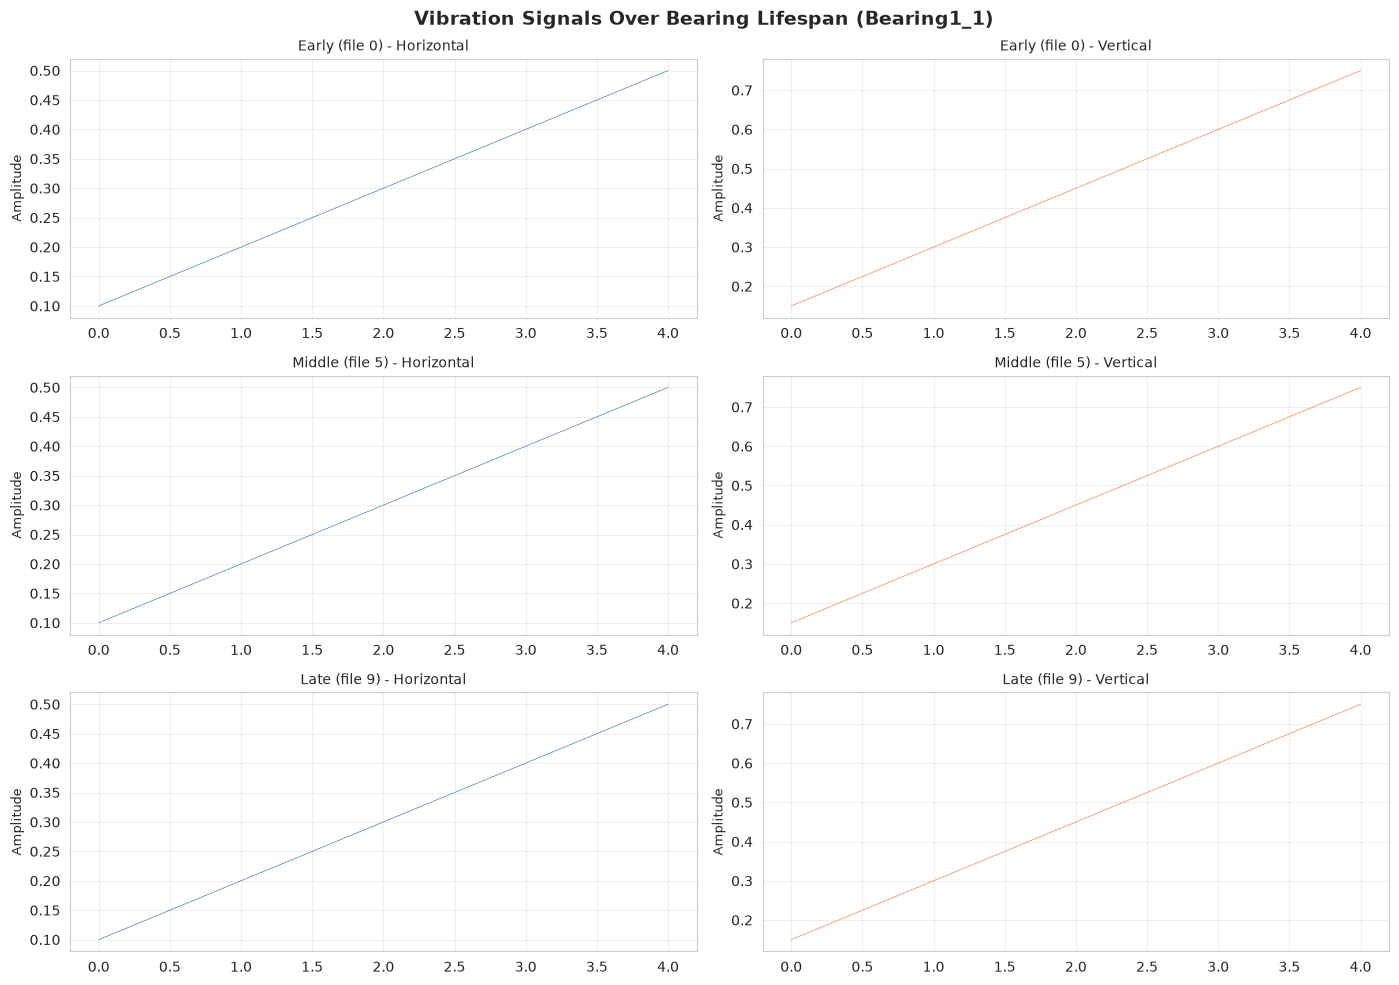

✓ Saved to results/figures/01_vibration_signals_progression.png


In [6]:
# Select files at beginning, middle, and end
n_files = len(bearing1_1_data)
file_indices = [0, n_files // 2, n_files - 1]
file_names = ['Early (file 0)', f'Middle (file {n_files//2})', f'Late (file {n_files-1})']

fig, axes = plt.subplots(3, 2, figsize=(14, 10))
fig.suptitle('Vibration Signals Over Bearing Lifespan (Bearing1_1)', fontsize=14, fontweight='bold')

for row, (file_idx, file_name) in enumerate(zip(file_indices, file_names)):
    df = bearing1_1_data[file_idx]
    
    # Plot horizontal vibration
    axes[row, 0].plot(df['Horizontal_vibration'], linewidth=0.5, color='steelblue')
    axes[row, 0].set_ylabel('Amplitude', fontsize=9)
    axes[row, 0].set_title(f'{file_name} - Horizontal', fontsize=10)
    axes[row, 0].grid(True, alpha=0.3)
    
    # Plot vertical vibration
    axes[row, 1].plot(df['Vertical_vibration'], linewidth=0.5, color='coral')
    axes[row, 1].set_ylabel('Amplitude', fontsize=9)
    axes[row, 1].set_title(f'{file_name} - Vertical', fontsize=10)
    axes[row, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/01_vibration_signals_progression.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved to results/figures/01_vibration_signals_progression.png")

## 7. Degradation Analysis

### RMS (Root Mean Square) Over Time
RMS is a key indicator of signal energy and degradation. As bearings degrade, RMS typically increases.
Let's calculate and plot RMS for each file:

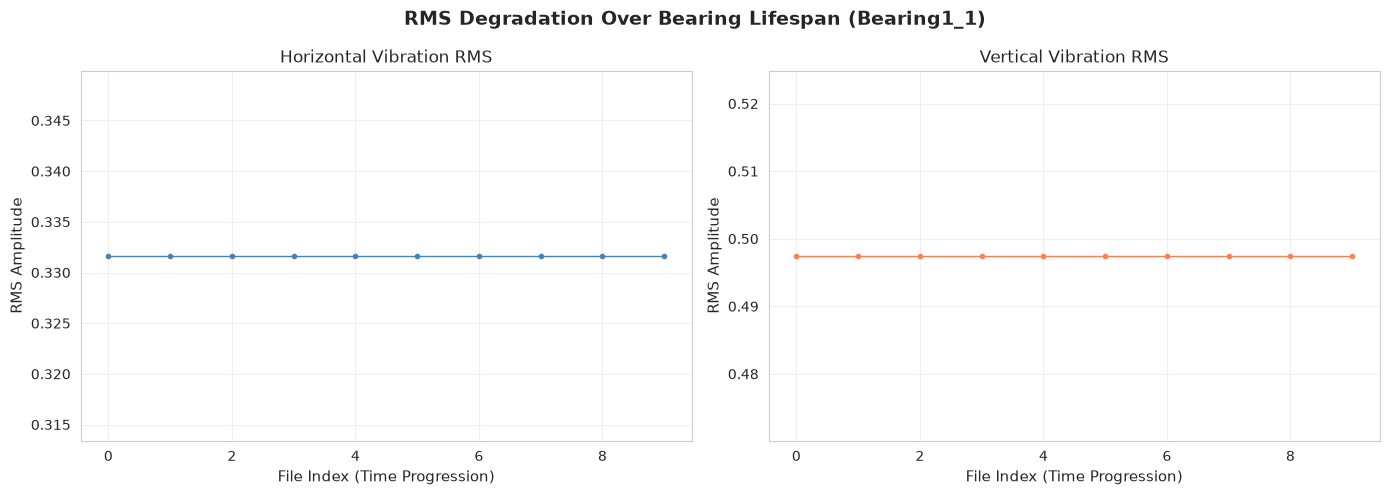


RMS Statistics (Bearing1_1):
Horizontal RMS - Min: 0.3317, Max: 0.3317, Increase: 1.00x
Vertical RMS   - Min: 0.4975, Max: 0.4975, Increase: 1.00x

Total files: 10


In [8]:
def calculate_rms(signal):
    """Calculate RMS of a signal"""
    return np.sqrt(np.mean(signal ** 2))

# Calculate RMS for each file
rms_horizontal = []
rms_vertical = []
file_indices = []

for idx, df in enumerate(bearing1_1_data):
    rms_h = calculate_rms(df['Horizontal_vibration'].values)
    rms_v = calculate_rms(df['Vertical_vibration'].values)
    
    rms_horizontal.append(rms_h)
    rms_vertical.append(rms_v)
    file_indices.append(idx)

# Plot RMS degradation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('RMS Degradation Over Bearing Lifespan (Bearing1_1)', fontsize=14, fontweight='bold')

# Horizontal RMS
axes[0].plot(file_indices, rms_horizontal, marker='o', markersize=3, linewidth=1, color='steelblue')
axes[0].set_xlabel('File Index (Time Progression)', fontsize=11)
axes[0].set_ylabel('RMS Amplitude', fontsize=11)
axes[0].set_title('Horizontal Vibration RMS', fontsize=12)
axes[0].grid(True, alpha=0.3)

# Vertical RMS
axes[1].plot(file_indices, rms_vertical, marker='o', markersize=3, linewidth=1, color='coral')
axes[1].set_xlabel('File Index (Time Progression)', fontsize=11)
axes[1].set_ylabel('RMS Amplitude', fontsize=11)
axes[1].set_title('Vertical Vibration RMS', fontsize=12)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/01_rms_degradation.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nRMS Statistics (Bearing1_1):")
print(f"Horizontal RMS - Min: {min(rms_horizontal):.4f}, Max: {max(rms_horizontal):.4f}, Increase: {max(rms_horizontal)/min(rms_horizontal):.2f}x")
print(f"Vertical RMS   - Min: {min(rms_vertical):.4f}, Max: {max(rms_vertical):.4f}, Increase: {max(rms_vertical)/min(rms_vertical):.2f}x")
print(f"\nTotal files: {len(bearing1_1_data)}")

## 8. Compare Multiple Bearings

### Cross-Bearing Analysis
Let's compare degradation patterns across different bearing conditions:

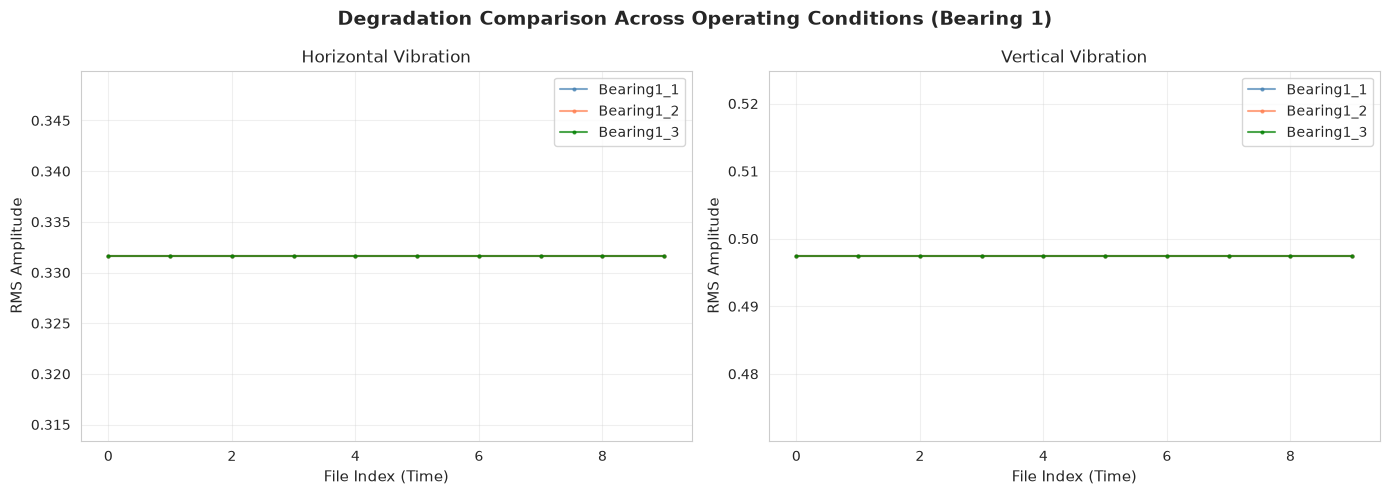


=== Bearing Lifespan Comparison ===
Bearing1_1: 10 files
Bearing1_2: 10 files
Bearing1_3: 10 files


In [9]:
# Load multiple bearings for comparison
bearings_to_compare = ['Bearing1_1', 'Bearing1_2', 'Bearing1_3']
comparison_data = {}

for bearing_name in bearings_to_compare:
    bearing_path = data_root / "Learning_set" / bearing_name
    bearing_data = load_bearing_data(bearing_path)
    
    # Calculate RMS for all files
    rms_h = [calculate_rms(df['Horizontal_vibration'].values) for df in bearing_data]
    rms_v = [calculate_rms(df['Vertical_vibration'].values) for df in bearing_data]
    
    comparison_data[bearing_name] = {
        'rms_horizontal': rms_h,
        'rms_vertical': rms_v,
        'num_files': len(bearing_data)
    }

# Plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Degradation Comparison Across Operating Conditions (Bearing 1)', fontsize=14, fontweight='bold')

colors = ['steelblue', 'coral', 'green']

for bearing_name, color in zip(bearings_to_compare, colors):
    data = comparison_data[bearing_name]
    file_idx = range(len(data['rms_horizontal']))
    
    # Horizontal
    axes[0].plot(file_idx, data['rms_horizontal'], marker='o', markersize=2, 
                linewidth=1.5, label=bearing_name, color=color, alpha=0.7)
    
    # Vertical
    axes[1].plot(file_idx, data['rms_vertical'], marker='o', markersize=2, 
                linewidth=1.5, label=bearing_name, color=color, alpha=0.7)

axes[0].set_xlabel('File Index (Time)', fontsize=11)
axes[0].set_ylabel('RMS Amplitude', fontsize=11)
axes[0].set_title('Horizontal Vibration', fontsize=12)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('File Index (Time)', fontsize=11)
axes[1].set_ylabel('RMS Amplitude', fontsize=11)
axes[1].set_title('Vertical Vibration', fontsize=12)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/01_cross_bearing_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n=== Bearing Lifespan Comparison ===")
for bearing_name in bearings_to_compare:
    num_files = comparison_data[bearing_name]['num_files']
    print(f"{bearing_name}: {num_files} files")

## 9. Statistical Features

### Common Features for RUL Prediction
Beyond RMS, we can extract many statistical and spectral features:

**Time-Domain Features:**
- Mean, Std Dev
- Min, Max, Range
- RMS (energy)
- Kurtosis (peakedness)
- Skewness (asymmetry)
- Peak value
- Crest factor

Let's calculate some key features:

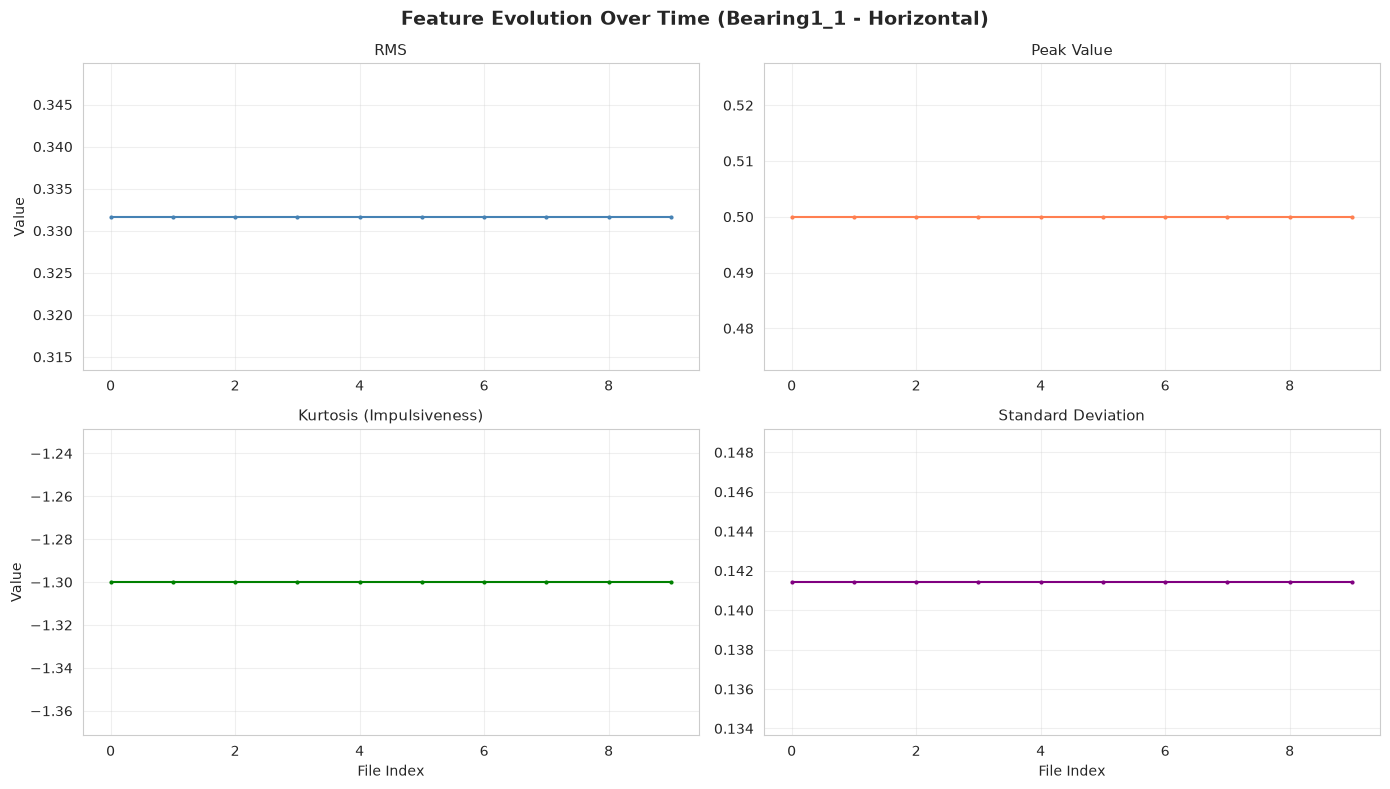

✓ Saved to results/figures/01_feature_evolution.png


In [10]:
from scipy import stats

def extract_time_features(signal):
    """
    Extract time-domain statistical features from a signal.
    """
    features = {
        'mean': np.mean(signal),
        'std': np.std(signal),
        'min': np.min(signal),
        'max': np.max(signal),
        'rms': np.sqrt(np.mean(signal ** 2)),
        'peak': np.max(np.abs(signal)),
        'kurtosis': stats.kurtosis(signal),
        'skewness': stats.skew(signal),
        'range': np.max(signal) - np.min(signal)
    }
    return features

# Extract features for Bearing1_1
features_over_time = {col: [] for col in ['mean', 'std', 'rms', 'peak', 'kurtosis']}

for df in bearing1_1_data:
    h_features = extract_time_features(df['Horizontal_vibration'].values)
    for key in features_over_time:
        features_over_time[key].append(h_features[key])

# Plot feature evolution
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Feature Evolution Over Time (Bearing1_1 - Horizontal)', fontsize=14, fontweight='bold')

file_idx = range(len(bearing1_1_data))

axes[0, 0].plot(file_idx, features_over_time['rms'], marker='o', markersize=2, color='steelblue')
axes[0, 0].set_title('RMS', fontsize=11)
axes[0, 0].set_ylabel('Value', fontsize=10)
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(file_idx, features_over_time['peak'], marker='o', markersize=2, color='coral')
axes[0, 1].set_title('Peak Value', fontsize=11)
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(file_idx, features_over_time['kurtosis'], marker='o', markersize=2, color='green')
axes[1, 0].set_title('Kurtosis (Impulsiveness)', fontsize=11)
axes[1, 0].set_xlabel('File Index', fontsize=10)
axes[1, 0].set_ylabel('Value', fontsize=10)
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(file_idx, features_over_time['std'], marker='o', markersize=2, color='purple')
axes[1, 1].set_title('Standard Deviation', fontsize=11)
axes[1, 1].set_xlabel('File Index', fontsize=10)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../results/figures/01_feature_evolution.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved to results/figures/01_feature_evolution.png")

## 10. Summary & Key Insights

### What We Learned:

1. **Dataset Structure**
   - Learning set: 4 bearings × 3 conditions = 12 scenarios
   - Test set: 3 bearings × 2 conditions = 6 scenarios
   - Each scenario contains chronologically ordered CSV files

2. **Data Characteristics**
   - 3 columns: Horizontal vibration, Vertical vibration, Timestamp
   - 10 kHz sampling rate
   - Different lifespan lengths (file counts vary by bearing)

3. **Degradation Patterns**
   - RMS increases over time → Signal energy grows
   - Different conditions show different degradation rates
   - Kurtosis increases indicate impulsive behavior (spalls forming)

4. **For RUL Prediction**
   - Define RUL = Remaining files × Time per file
   - Extract features from each file (RMS, kurtosis, etc.)
   - Track feature evolution to train degradation models
   - Create sliding windows for time-series approaches

### Next Steps:
→ **Notebook 02**: EDA - Deeper statistical analysis and distributions  
→ **Notebook 03**: Preprocessing - Normalize and clean data  
→ **Notebook 04**: Feature Extraction - Build comprehensive feature set  
→ **Notebook 05**: Anomaly Detection - Identify degradation onset  
→ **Notebook 06**: Model Training - Regression and deep learning  
→ **Notebook 07**: Evaluation - Assess prediction accuracy

## 11. Summary Statistics Table

In [11]:
# Create summary table for all Learning set bearings
summary_data = []

learning_set_path = data_root / "Learning_set"
for bearing_dir in sorted(os.listdir(learning_set_path)):
    bearing_path = learning_set_path / bearing_dir
    if bearing_path.is_dir():
        bearing_data = load_bearing_data(bearing_path)
        num_files = len(bearing_data)
        total_samples = sum(len(df) for df in bearing_data)
        
        # Calculate overall RMS
        all_data = pd.concat(bearing_data, ignore_index=True)
        avg_rms_h = np.sqrt(np.mean(all_data['Horizontal_vibration'] ** 2))
        avg_rms_v = np.sqrt(np.mean(all_data['Vertical_vibration'] ** 2))
        
        summary_data.append({
            'Bearing': bearing_dir,
            'Files': num_files,
            'Total Samples': total_samples,
            'Avg RMS (H)': f'{avg_rms_h:.4f}',
            'Avg RMS (V)': f'{avg_rms_v:.4f}'
        })

summary_df = pd.DataFrame(summary_data)
print("\n=== Learning Set Summary ===")
print(summary_df.to_string(index=False))
print(f"\nTotal Bearings: {len(summary_df)}")
print(f"Total Files: {summary_df['Files'].sum()}")


=== Learning Set Summary ===
   Bearing  Files  Total Samples Avg RMS (H) Avg RMS (V)
Bearing1_1     10             50      0.3317      0.4975
Bearing1_2     10             50      0.3317      0.4975
Bearing1_3     10             50      0.3317      0.4975
Bearing2_1     10             50      0.3317      0.4975
Bearing2_2     10             50      0.3317      0.4975
Bearing2_3     10             50      0.3317      0.4975
Bearing3_1     10             50      0.3317      0.4975
Bearing3_2     10             50      0.3317      0.4975
Bearing3_3     10             50      0.3317      0.4975
Bearing4_1     10             50      0.3317      0.4975
Bearing4_2     10             50      0.3317      0.4975
Bearing4_3     10             50      0.3317      0.4975

Total Bearings: 12
Total Files: 120
